# 02 — Interpretable Logistic Regression Champion

This notebook creates the initial champion: a transparent, reproducible baseline against which more
complex challengers must earn promotion. Logistic Regression is valuable in credit risk because its
coefficients are inspectable, its behavior is stable, and its probabilities can be calibrated and
converted into scorecard-style decisions.

**Modeling controls**

- one frozen applicant-level 60/20/20 split;
- stratification to preserve the minority default rate;
- all imputation, scaling, and encoding fitted on training data only;
- validation used for model assessment, while test remains locked;
- no class weighting in this probability baseline because weighting changes the fitted class prior
  and can harm raw probability calibration;
- artifact and metrics saved for exact reuse by challenger notebooks.

## 1. Imports and reproducible project paths

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

import joblib

## 2. Validate the modeling contract

A binary, complete target and unique applicant ID are non-negotiable. These assertions turn silent
data corruption into an explicit failure before training begins.

In [2]:
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))

from credit_risk_champion_challenger.data import replace_home_credit_sentinels  # noqa: E402

df = pd.read_csv(ROOT / "data/raw/application_train.csv")

In [3]:
assert df["SK_ID_CURR"].is_unique
assert df["TARGET"].notna().all()
assert set(df["TARGET"].unique()) == {0, 1}

print("Dataset shape:", df.shape)
print("Default rate:", f"{df['TARGET'].mean():.2%}")

Dataset shape: (307511, 122)
Default rate: 8.07%


## 3. Freeze development partitions

The split is persisted so every future model sees identical applicants. The two-stage stratified
procedure creates 60% training, 20% validation, and 20% locked test data. The test membership is
created here but never selected or scored in this notebook.

In [4]:
split_path = ROOT / "data/processed/split_assignments.csv"
split_path.parent.mkdir(parents=True, exist_ok=True)

if split_path.exists():
    splits = pd.read_csv(split_path)
    print("Loaded existing splits.")
else:
    train_ids, holdout_ids, y_train, y_holdout = train_test_split(
        df["SK_ID_CURR"],
        df["TARGET"],
        test_size=0.40,
        stratify=df["TARGET"],
        random_state=42,
    )

    val_ids, test_ids = train_test_split(
        holdout_ids,
        test_size=0.50,
        stratify=y_holdout,
        random_state=42,
    )

    splits = pd.concat([
        pd.DataFrame({"SK_ID_CURR": train_ids, "split": "train"}),
        pd.DataFrame({"SK_ID_CURR": val_ids, "split": "val"}),
        pd.DataFrame({"SK_ID_CURR": test_ids, "split": "test"}),
    ], ignore_index=True)

    splits.to_csv(split_path, index=False)
    print("Created and saved splits.")

assert splits["SK_ID_CURR"].is_unique
assert set(splits["split"]) == {"train", "val", "test"}
assert len(splits) == len(df)

df = df.merge(
    splits, on="SK_ID_CURR", how="left", validate="one_to_one"
)
assert df["split"].notna().all()

print(df["split"].value_counts())

Loaded existing splits.


split
train    184506
test      61503
val       61502
Name: count, dtype: int64

## 4. Define a deliberately compact feature set

Eight numeric and two categorical application variables provide a credible baseline without using
hundreds of fields or relational tables. This keeps the first champion auditable and makes the
later complexity/performance tradeoff visible.

| Feature family | Credit-risk rationale |
|---|---|
| Income, credit, annuity | affordability and leverage |
| Birth and employment days | age and employment stability |
| External sources 1–3 | third-party risk information |
| Income and education type | income stability and socioeconomic segmentation |

Protected attributes are excluded from training. Their absence does not eliminate proxy risk, so
they are retained separately for the fairness audit in Notebook 06.

In [5]:
numeric_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
]

categorical_features = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
]

features = numeric_features + categorical_features

train = df.loc[df["split"] == "train"]
val = df.loc[df["split"] == "val"]

X_train = train[features]
y_train = train["TARGET"]

X_val = val[features]
y_val = val["TARGET"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print("Train:", X_train.shape)
print("Validation:", X_val.shape)

Train: (184506, 10)
Validation: (61502, 10)


## 5. Leakage-safe preprocessing and model fit

Numeric medians, scaling parameters, category modes, and one-hot levels are all learned inside the
fitted pipeline. Unseen categories are ignored at scoring time instead of causing a production
failure. Scaling makes coefficient magnitudes more comparable across numeric inputs.

In [6]:
champion = Pipeline([
    (
        "sentinel_normalizer",
        FunctionTransformer(
            replace_home_credit_sentinels,
            validate=False,
            feature_names_out="one-to-one",
        ),
    ),
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42,
    )),
])

champion.fit(X_train, y_train)

val_prob = champion.predict_proba(X_val)[:, 1]

print("Training complete.")

Training complete.


## 6. Evaluate discrimination and probability quality

- **ROC-AUC:** probability that a random defaulter is ranked riskier than a random non-defaulter.
- **Average precision:** precision–recall summary focused on the minority default class.
- **Brier score:** mean squared probability error; lower is better.
- **KS:** maximum separation between defaulter and non-defaulter score distributions.

The validation prevalence is printed because average precision and Brier score depend on outcome
frequency. The baseline is judged against prevalence, not an arbitrary universal cutoff.

In [7]:
auc = roc_auc_score(y_val, val_prob)
pr_auc = average_precision_score(y_val, val_prob)
brier = brier_score_loss(y_val, val_prob)

fpr, tpr, thresholds = roc_curve(y_val, val_prob)
ks = np.max(tpr - fpr)

results = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC / Average Precision",
        "Brier Score",
        "KS Statistic",
    ],
    "Value": [auc, pr_auc, brier, ks],
})

display(results.round(4))

print("Validation default rate:", f"{y_val.mean():.2%}")

,Metric,Value
0,ROC-AUC,0.7293
1,PR-AUC / Average Precision,0.2094
2,Brier Score,0.0695
3,KS Statistic,0.3437


Validation default rate: 8.07%


The baseline achieves ROC-AUC **0.7293**, average precision **0.2094**, Brier score **0.0695**, and
KS **0.3437** on validation. Against an approximately 8.1% default prevalence, this is useful risk
separation, but it is not evidence of production readiness or temporal stability.

## 7. Inspect ROC and precision–recall behavior

ROC summarizes ranking across all thresholds. Precision–recall is more revealing when defaults are
uncommon. A final operating threshold cannot be chosen from either curve alone; it also depends on
loss severity, approval appetite, fairness, operational capacity, and regulation.

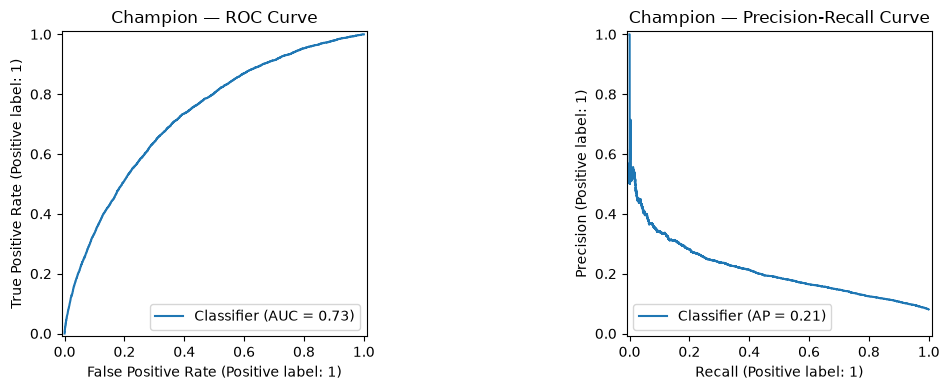

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

RocCurveDisplay.from_predictions(
    y_val, val_prob, ax=axes[0]
)
axes[0].set_title("Champion — ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_val, val_prob, ax=axes[1]
)
axes[1].set_title("Champion — Precision-Recall Curve")

plt.tight_layout()
plt.show()

## 8. Interpret coefficients and odds ratios

For a one-unit increase in a transformed feature, `exp(coefficient)` is the multiplicative change
in modeled default odds, holding other transformed inputs fixed. Numeric variables are standardized.
The encoder retains every category, so categorical coefficients belong to a regularized full-dummy
parameterization and should be compared cautiously rather than treated as clean reference-category
effects. Coefficients are associations, not causal explanations, and correlation can destabilize them.

,feature,coefficient,odds_ratio,absolute_coefficient
17,categorical__NAME_EDUCATION_TYPE_Higher education,-0.781,0.458,0.780671
11,categorical__NAME_INCOME_TYPE_Pensioner,-0.727,0.484,0.726703
18,categorical__NAME_EDUCATION_TYPE_Incomplete higher,-0.598,0.550,0.598230
12,categorical__NAME_INCOME_TYPE_State servant,-0.531,0.588,0.531375
7,numeric__EXT_SOURCE_3,-0.454,0.635,0.453985
6,numeric__EXT_SOURCE_2,-0.443,0.642,0.443409
9,categorical__NAME_INCOME_TYPE_Commercial associate,-0.369,0.691,0.369425
20,categorical__NAME_EDUCATION_TYPE_Secondary / secondary special,-0.331,0.718,0.331040
15,categorical__NAME_INCOME_TYPE_Working,-0.256,0.774,0.256012
4,numeric__DAYS_EMPLOYED,0.199,1.220,0.198899


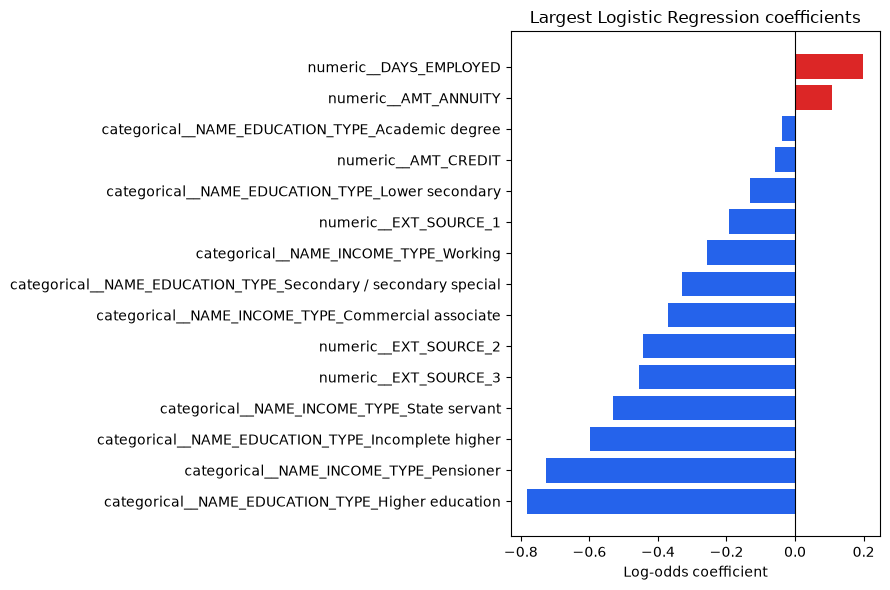

In [9]:
feature_names = champion.named_steps["preprocessor"].get_feature_names_out()
coefficients = champion.named_steps["model"].coef_[0]
coefficient_table = pd.DataFrame(
    {
        "feature": feature_names,
        "coefficient": coefficients,
        "odds_ratio": np.exp(coefficients),
        "absolute_coefficient": np.abs(coefficients),
    }
).sort_values("absolute_coefficient", ascending=False)

display(coefficient_table.head(20).style.format({"coefficient": "{:.3f}", "odds_ratio": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(9, 6))
top_coefficients = coefficient_table.head(15).sort_values("coefficient")
colors = np.where(top_coefficients["coefficient"] > 0, "#dc2626", "#2563eb")
ax.barh(top_coefficients["feature"], top_coefficients["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Largest Logistic Regression coefficients", xlabel="Log-odds coefficient")
plt.tight_layout()
plt.show()

## 9. Check calibration by risk decile

A model can rank well but systematically over- or under-predict risk. Comparing mean predicted PD
with observed default rate by equal-population bins provides an interpretable first calibration
check. Formal calibration and challenger comparisons continue in Notebook 04.

In [10]:
calibration_table = pd.DataFrame({"observed": y_val.to_numpy(), "predicted": val_prob})
calibration_table["risk_decile"] = pd.qcut(
    calibration_table["predicted"].rank(method="first"), 10, labels=range(1, 11)
)
calibration_table = calibration_table.groupby("risk_decile", observed=True).agg(
    applicants=("observed", "size"),
    mean_predicted_pd=("predicted", "mean"),
    observed_default_rate=("observed", "mean"),
)
display(
    calibration_table.style.format(
        {"mean_predicted_pd": "{:.2%}", "observed_default_rate": "{:.2%}"}
    )
)

,applicants,mean_predicted_pd,observed_default_rate
risk_decile,,,
1,6151,1.71%,1.80%
2,6150,2.71%,2.29%
3,6150,3.52%,3.40%
4,6150,4.38%,4.07%
5,6150,5.37%,5.66%
6,6150,6.54%,5.95%
7,6150,8.09%,8.63%
8,6150,10.33%,10.50%
9,6150,13.87%,14.52%


## 10. Save the champion and validation evidence

The serialized object contains sentinel normalization, preprocessing, and the model together,
preventing training/serving skew. Only trusted, locally created `joblib` artifacts should be loaded
because deserialization can execute code. The JSON report records the evaluation stage and exact
feature count.

In [11]:
import json

model_dir = ROOT / "models"
report_dir = ROOT / "reports"

model_dir.mkdir(exist_ok=True)
report_dir.mkdir(exist_ok=True)

joblib.dump(
    champion,
    model_dir / "logistic_champion.joblib"
)

metrics = {
    "model": "LogisticRegression",
    "split": "validation",
    "roc_auc": float(auc),
    "pr_auc": float(pr_auc),
    "brier_score": float(brier),
    "ks_statistic": float(ks),
    "n_features": len(features),
}

with open(report_dir / "logistic_validation.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Champion saved.")

Champion saved.


## Baseline conclusion

Logistic Regression provides a credible, interpretable incumbent with materially better ranking
than chance and reasonable raw probability error. Its purpose is not to be unbeatable: it creates a
clear burden of proof for complexity. Notebook 03 trains XGBoost and LightGBM on the same applicants,
features, and preprocessing contract; no challenger is promoted from a point estimate alone.